# Sampling Point Against a Fixed Timepoint

In [1]:
## SHARED CONFIG ##

import importlib

import analyse_pr_config
importlib.reload(analyse_pr_config)
from analyse_pr_config import (REPLICATES, SAMPLING_METHOD, biomass_and_floor,
                               pooled_blank_and_threshold)


## CONFIG ##

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bioutils import spectramax, transform
from bioutils.microplate import get_adjacent_wells, get_circuit_wells

OUT_DIR = Path("out")
OUT_DIR.mkdir(exist_ok=True)

CONDITIONS = ("None", "aTc", "IPTG", "Both")
BLANK_WELLS = get_adjacent_wells(15, 20, 4)

PLATE = {"label": "AL1",
         "file": next(rep["file"] for rep in REPLICATES if rep["label"] == "AL1"),
         "od_table_lines": (2, 44)}

GROUPS = {"Circuit 77": get_circuit_wells(77), "Circuit 10": get_circuit_wells(10)}

# left: one circuit across conditions. right: one condition across circuits.
PANELS = ((("Circuit 77", "None", "-"), ("Circuit 77", "Both", "--")),
          (("Circuit 77", "Both", "--"), ("Circuit 10", "Both", ":")))


## FIGURE ##

# A4 text width at 25 mm margins, placed 1:1
FIGURE_INCHES = (6.3, 3.2)
PRINT_DPI = 300
plt.rcParams.update({"figure.dpi": 100, "font.size": 8, "axes.labelsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8})

## Load

In [2]:
lines = spectramax.read_plate_file(PLATE["file"])
start, end = PLATE["od_table_lines"]
table = spectramax.parse_tsv_table(lines[start - 1:end])
od_raw = spectramax.reshape(table["data"], 16, 24)
t_minutes = spectramax.time_to_minutes(table["time"])

blank_rows, blank_cols = zip(*BLANK_WELLS)
pooled_blank, detection_threshold = pooled_blank_and_threshold(
    od_raw[list(blank_rows), list(blank_cols), :], PLATE["label"])

biomass = {}
for group, wells in GROUPS.items():
    rows, cols = zip(*wells)
    # smoothed, pooled-blank-corrected, and the floor tested on that same series
    corrected, above = biomass_and_floor(od_raw[list(rows), list(cols), :],
                                         pooled_blank, detection_threshold)
    biomass[group] = np.where(above, corrected, np.nan)

sampled = pd.read_csv(OUT_DIR / "analyse_pr_biomass.csv",
                      keep_default_na=False, na_values=[""]).set_index(
    ["Group", "Rep", "Condition"])

print(f"{PLATE['label']}: {od_raw.shape}, runtime {t_minutes[-1]:.0f} min")

AL1: (16, 24, 41), runtime 480 min


## Figure

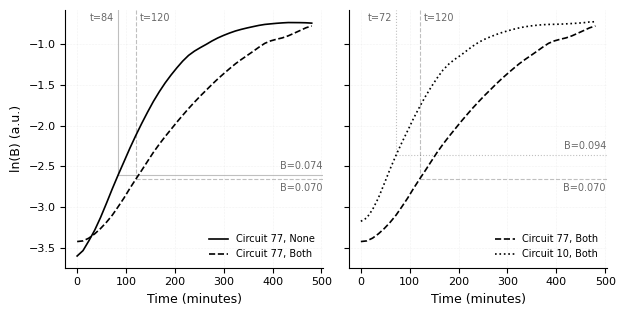

In [3]:
fig, axes = plt.subplots(1, 2, figsize=FIGURE_INCHES, sharey=True)
marks = []
for ax, wells in zip(axes, PANELS):
    for group, condition, style in wells:
        series = biomass[group][CONDITIONS.index(condition)]
        row = sampled.loc[(group, PLATE["label"], condition)]
        ax.plot(t_minutes, np.log(series), color="black", ls=style, lw=1.2,
                label=f"{group}, {condition}")
        marks.append((ax, row, style))

    ax.set_xlabel("Time (minutes)")
    ax.legend(fontsize=7, frameon=False, loc="lower right")
    ax.grid(True, ls=":", alpha=0.3, lw=0.4)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[0].set_ylabel("ln(B) (a.u.)")

lowest, earliest = {}, {}
for ax, row, _ in marks:
    lowest[id(ax)] = min(lowest.get(id(ax), np.inf),
                         getattr(row, f"biomass_at_sampled_{SAMPLING_METHOD}"))
    earliest[id(ax)] = min(earliest.get(id(ax), np.inf),
                           getattr(row, f"t_sampled_{SAMPLING_METHOD}"))

for ax in axes:
    ax.set_xlim(ax.get_xlim())
    ax.set_ylim(ax.get_ylim())

for ax, row, style in marks:
    sampled_t = getattr(row, f"t_sampled_{SAMPLING_METHOD}")
    sampled_b = getattr(row, f"biomass_at_sampled_{SAMPLING_METHOD}")
    sampled_y = np.log(sampled_b)
    low_x, high_x = ax.get_xlim()
    low_y, high_y = ax.get_ylim()
    ax.axvline(sampled_t, ymin=(sampled_y - low_y) / (high_y - low_y), ymax=1.0,
               color="black", ls=style, lw=0.8, alpha=0.25, zorder=0)
    ax.axhline(sampled_y, xmin=(sampled_t - low_x) / (high_x - low_x), xmax=1.0,
               color="black", ls=style, lw=0.8, alpha=0.25, zorder=0)

    left = sampled_t == earliest[id(ax)]
    ax.annotate(f"t={sampled_t:.0f}", (sampled_t, 1.0), xycoords=("data", "axes fraction"),
                ha="right" if left else "left", va="top", fontsize=7, color="dimgray",
                xytext=(-3 if left else 3, -2), textcoords="offset points")
    below = sampled_b == lowest[id(ax)]
    ax.annotate(f"B={sampled_b:.3f}", (0.995, sampled_y),
                xycoords=("axes fraction", "data"), ha="right",
                va="top" if below else "bottom", fontsize=7, color="dimgray",
                xytext=(0, -3 if below else 3), textcoords="offset points")

plt.tight_layout()
fig.savefig(OUT_DIR / "analyse_pr_biomass_naive.pdf", dpi=PRINT_DPI, bbox_inches="tight")
plt.show()